## import the segment wise absolute correlation matrices

In [1]:
from pathlib import Path
import pandas as pd

abs_segment_base = Path('../correlation_matrices_segment_wise_absolute')
matrix_files = list(abs_segment_base.rglob('*.csv'))

if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} absolute matrices. Sample shape: {sample.shape}")


Found 2632 absolute matrices. Sample shape: (19, 19)


## filter the subjects for our study

In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

# Extract first 12 segments for session 1
n_segments = 12
subject_matrices = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    matrices = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        matrices.append(df.values)
        
    if matrices:
        avg_matrix = np.mean(matrices, axis=0)
        subject_matrices[subj] = pd.DataFrame(avg_matrix, index=df.index, columns=df.columns)
        
print(f"Processed {len(subject_matrices)} subjects")


Processed 20 subjects


## calculate edge strength for all edges of the filtered subjects

In [3]:
import networkx as nx
import numpy as np

subject_edge_strength = {}

for subj, df in subject_matrices.items():
    # Create graph from adjacency matrix
    G = nx.from_pandas_adjacency(df)
    
    # Calculate nearest-neighbor edge centrality (edge strength)
    es = {}
    for u, v, d in G.edges(data=True):
        wk = d.get('weight', 0)
        cvs_u = G.degree(u, weight='weight')
        cvs_v = G.degree(v, weight='weight')
        es[(u, v)] = ((cvs_u + cvs_v - 2 * wk) / (abs(cvs_u - cvs_v) + 1)) * wk
    
    # Store the result
    subject_edge_strength[subj] = es

print(f"Calculated edge strength for {len(subject_edge_strength)} subjects")

Calculated edge strength for 20 subjects


## plot edge strength heatmap

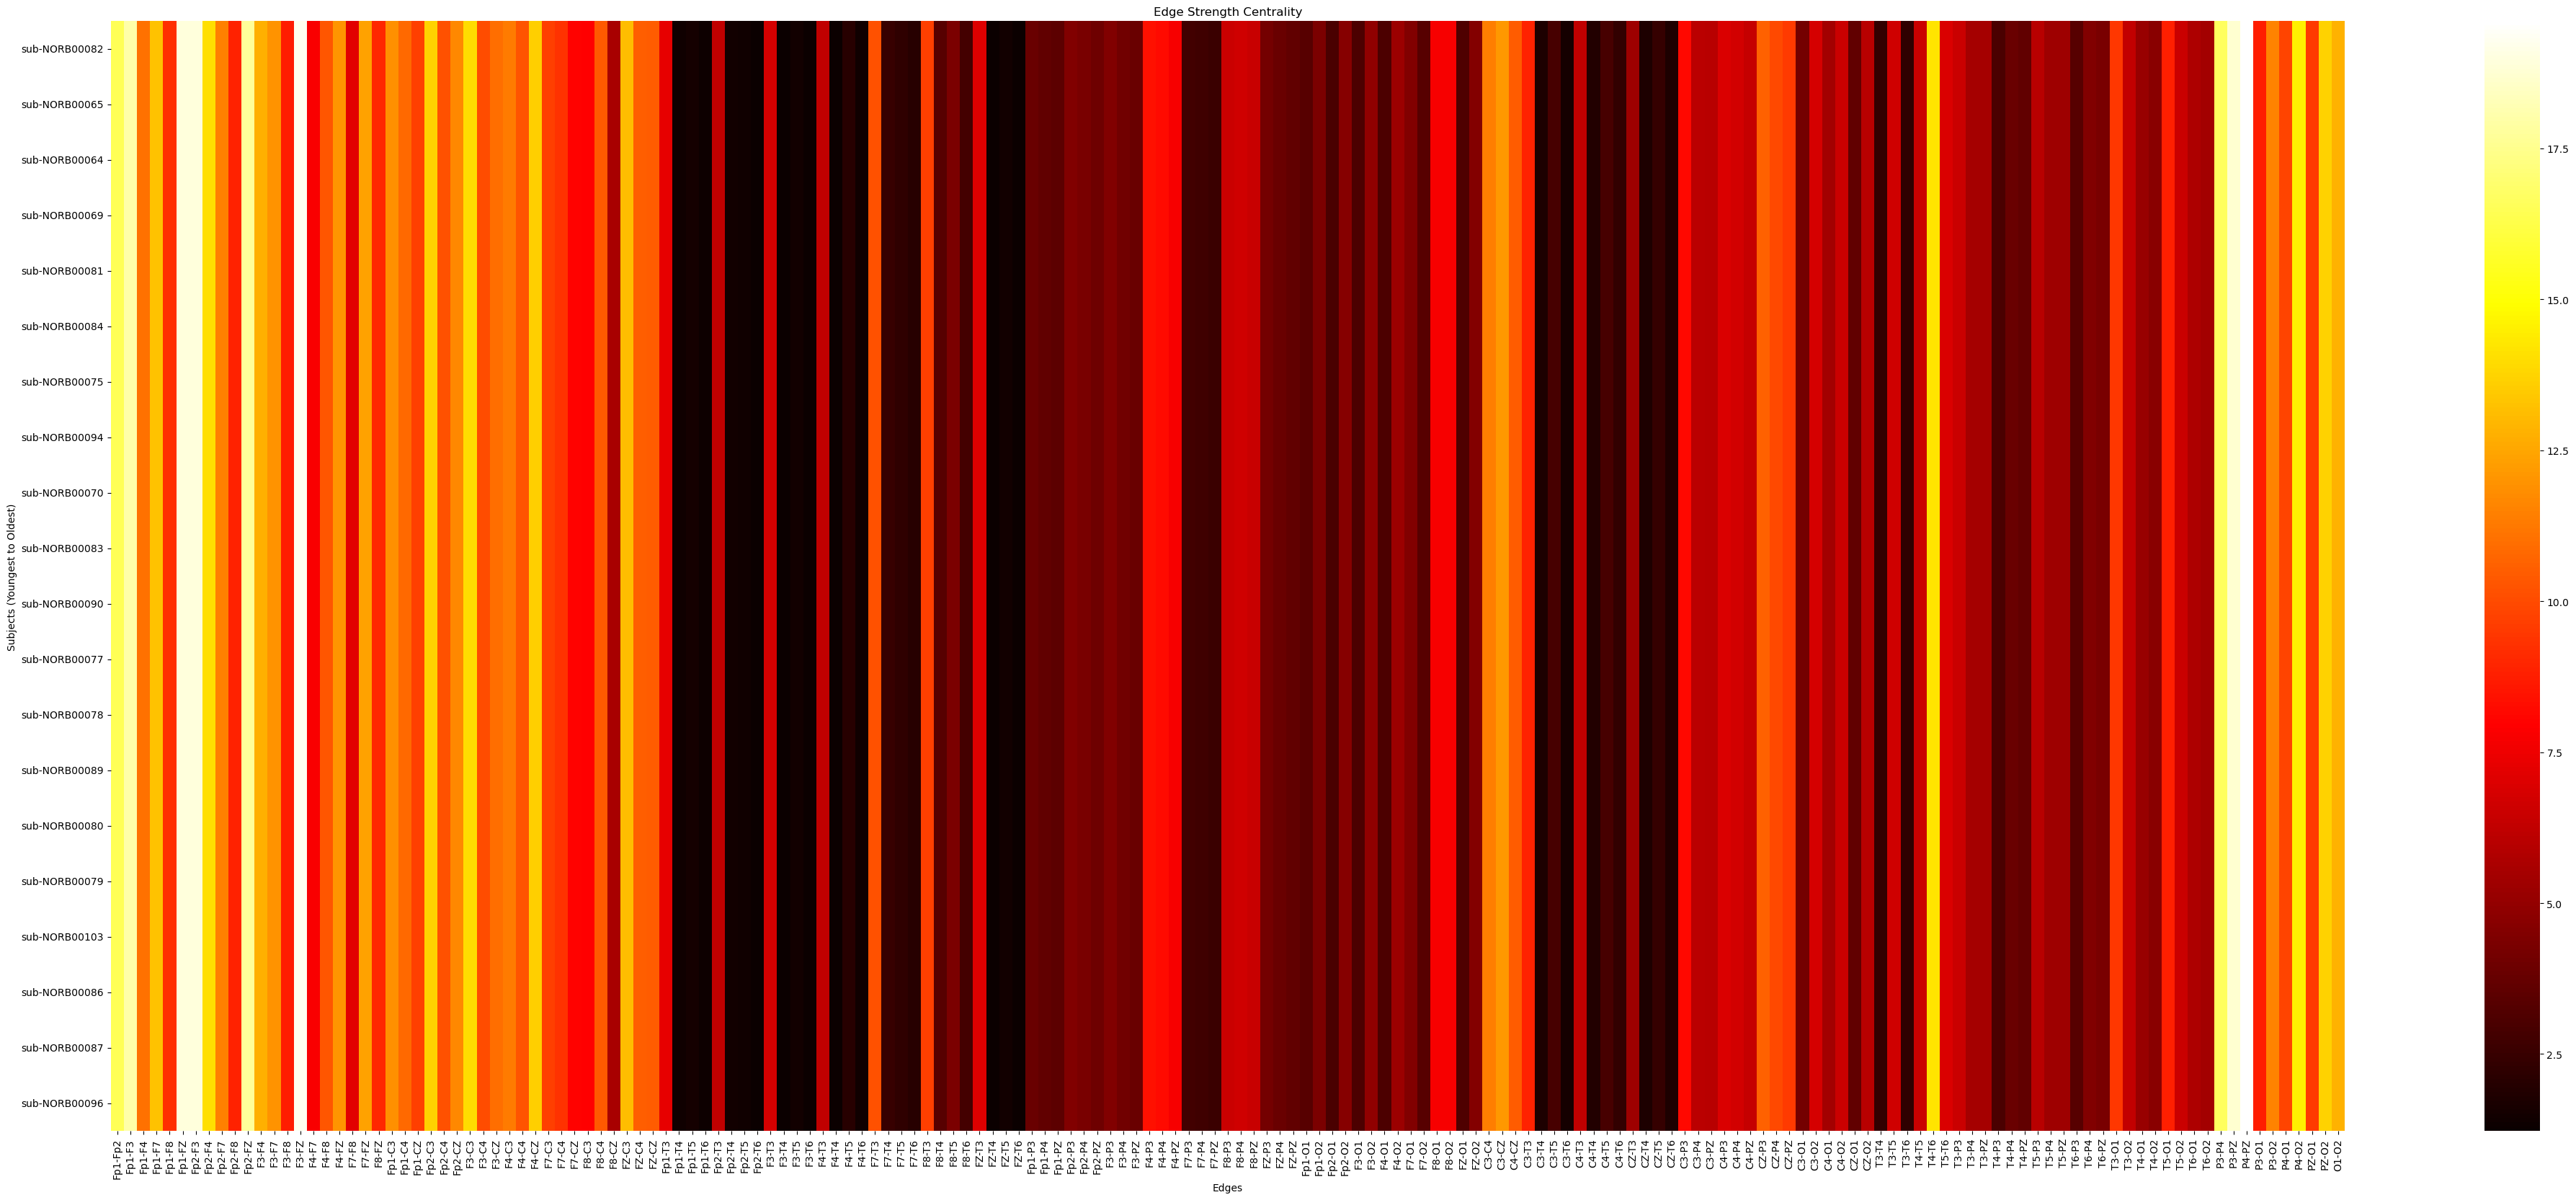

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Hardcoded edge order
edge_labels = [
    'Fp1-Fp2', 'Fp1-F3', 'Fp1-F4', 'Fp1-F7', 'Fp1-F8', 'Fp1-FZ', 'Fp2-F3',
    'Fp2-F4', 'Fp2-F7', 'Fp2-F8', 'Fp2-FZ', 'F3-F4', 'F3-F7', 'F3-F8', 'F3-FZ',
    'F4-F7', 'F4-F8', 'F4-FZ', 'F7-F8', 'F7-FZ', 'F8-FZ', 'Fp1-C3', 'Fp1-C4',
    'Fp1-CZ', 'Fp2-C3', 'Fp2-C4', 'Fp2-CZ', 'F3-C3', 'F3-C4', 'F3-CZ', 'F4-C3',
    'F4-C4', 'F4-CZ', 'F7-C3', 'F7-C4', 'F7-CZ', 'F8-C3', 'F8-C4', 'F8-CZ',
    'FZ-C3', 'FZ-C4', 'FZ-CZ', 'Fp1-T3', 'Fp1-T4', 'Fp1-T5', 'Fp1-T6',
    'Fp2-T3', 'Fp2-T4', 'Fp2-T5', 'Fp2-T6', 'F3-T3', 'F3-T4', 'F3-T5', 'F3-T6',
    'F4-T3', 'F4-T4', 'F4-T5', 'F4-T6', 'F7-T3', 'F7-T4', 'F7-T5', 'F7-T6',
    'F8-T3', 'F8-T4', 'F8-T5', 'F8-T6', 'FZ-T3', 'FZ-T4', 'FZ-T5', 'FZ-T6',
    'Fp1-P3', 'Fp1-P4', 'Fp1-PZ', 'Fp2-P3', 'Fp2-P4', 'Fp2-PZ', 'F3-P3',
    'F3-P4', 'F3-PZ', 'F4-P3', 'F4-P4', 'F4-PZ', 'F7-P3', 'F7-P4', 'F7-PZ',
    'F8-P3', 'F8-P4', 'F8-PZ', 'FZ-P3', 'FZ-P4', 'FZ-PZ', 'Fp1-O1', 'Fp1-O2',
    'Fp2-O1', 'Fp2-O2', 'F3-O1', 'F3-O2', 'F4-O1', 'F4-O2', 'F7-O1', 'F7-O2',
    'F8-O1', 'F8-O2', 'FZ-O1', 'FZ-O2', 'C3-C4', 'C3-CZ', 'C4-CZ', 'C3-T3',
    'C3-T4', 'C3-T5', 'C3-T6', 'C4-T3', 'C4-T4', 'C4-T5', 'C4-T6', 'CZ-T3',
    'CZ-T4', 'CZ-T5', 'CZ-T6', 'C3-P3', 'C3-P4', 'C3-PZ', 'C4-P3', 'C4-P4',
    'C4-PZ', 'CZ-P3', 'CZ-P4', 'CZ-PZ', 'C3-O1', 'C3-O2', 'C4-O1', 'C4-O2',
    'CZ-O1', 'CZ-O2', 'T3-T4', 'T3-T5', 'T3-T6', 'T4-T5', 'T4-T6', 'T5-T6',
    'T3-P3', 'T3-P4', 'T3-PZ', 'T4-P3', 'T4-P4', 'T4-PZ', 'T5-P3', 'T5-P4',
    'T5-PZ', 'T6-P3', 'T6-P4', 'T6-PZ', 'T3-O1', 'T3-O2', 'T4-O1', 'T4-O2',
    'T5-O1', 'T5-O2', 'T6-O1', 'T6-O2', 'P3-P4', 'P3-PZ', 'P4-PZ', 'P3-O1',
    'P3-O2', 'P4-O1', 'P4-O2', 'PZ-O1', 'PZ-O2', 'O1-O2',
]

# Load ages and sort subjects increasing (oldest top, youngest bottom)
ages_df = pd.read_csv('../age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
# User requested increasing order of their age
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_edge_strength:
        valid_subjects.append(subj)
        eb = subject_edge_strength[subj]
        row_data = []
        for e in edge_labels:
            u, v = e.split('-')
            val = es.get((u, v), es.get((v, u), 0))
            row_data.append(val)
        heatmap_data.append(row_data)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 20))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=valid_subjects)
plt.title('Edge Strength Centrality')
plt.xlabel('Edges')
plt.ylabel('Subjects (Youngest to Oldest)')
plt.show()

## calculate weighted jaccard index for edge strength

this cell calculates the weighted jaccard index (min/max) per segment for all 171 edges between every pair of subjects. 
for each edge, the jaccard index is computed for each of the 12 segments by dividing the minimum betweenness value by the maximum value. these 12 values are then averaged to give exactly 171 Jaccard indices per subject pair (one for each edge). finally, the average of these 171 indices is also computed.

In [5]:
import networkx as nx
import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path

# 1. Calculate edge strength for each segment individually for all filtered subjects
subject_segment_es = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    
    subject_segment_es[subj] = []
    
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        G = nx.from_pandas_adjacency(df)
        
        # Calculate nearest-neighbor edge centrality (edge strength)
        es = {}
        for u, v, d in G.edges(data=True):
            wk = d.get('weight', 0)
            cvs_u = G.degree(u, weight='weight')
            cvs_v = G.degree(v, weight='weight')
            es[(u, v)] = ((cvs_u + cvs_v - 2 * wk) / (abs(cvs_u - cvs_v) + 1)) * wk
        
        # Standardize edge tuple order to ensure consistency
        normalized_es = {}
        for (u, v), val in es.items():
            edge_tuple = tuple(sorted([u, v]))
            normalized_es[edge_tuple] = val
            
        subject_segment_es[subj].append(normalized_es)

print(f"Calculated individual segment edge strength for {len(subject_segment_es)} subjects.")

# 2. Calculate Weighted Jaccard Index for all pairs of subjects
sample_subj = formatted_subjects[0]
edges_list = list(subject_segment_es[sample_subj][0].keys())

pair_jaccard_avg = {}
pair_jaccard_all_edges = {}

# Iterate over all 20C2 pairs
for subj_A, subj_B in combinations(formatted_subjects, 2):
    edge_jaccards = []
    
    for e in edges_list:
        segment_jaccards = []
        
        for s in range(n_segments):
            if s < len(subject_segment_es[subj_A]) and s < len(subject_segment_es[subj_B]):
                val_A = subject_segment_es[subj_A][s].get(e, 0)
                val_B = subject_segment_es[subj_B][s].get(e, 0)
                
                if max(val_A, val_B) > 0:
                    jaccard_s = min(val_A, val_B) / max(val_A, val_B)
                else:
                    jaccard_s = 0
                segment_jaccards.append(jaccard_s)
        
        # Average the segment Jaccards for this edge
        edge_jaccard_avg = np.mean(segment_jaccards) if segment_jaccards else 0
        edge_jaccards.append(edge_jaccard_avg)
        
    pair_jaccard_all_edges[(subj_A, subj_B)] = edge_jaccards
    pair_jaccard_avg[(subj_A, subj_B)] = np.mean(edge_jaccards)

print(f"Calculated average Jaccard index for {len(pair_jaccard_avg)} subject pairs.")

Calculated individual segment edge strength for 20 subjects.
Calculated average Jaccard index for 190 subject pairs.


## plot jaccard index heatmap for subject pairs

plots the jaccard index for all 171 edges across all 190 subject pairs. the y-axis displays subject pairs sorted by the difference in their ages, with the smallest age difference at the bottom.

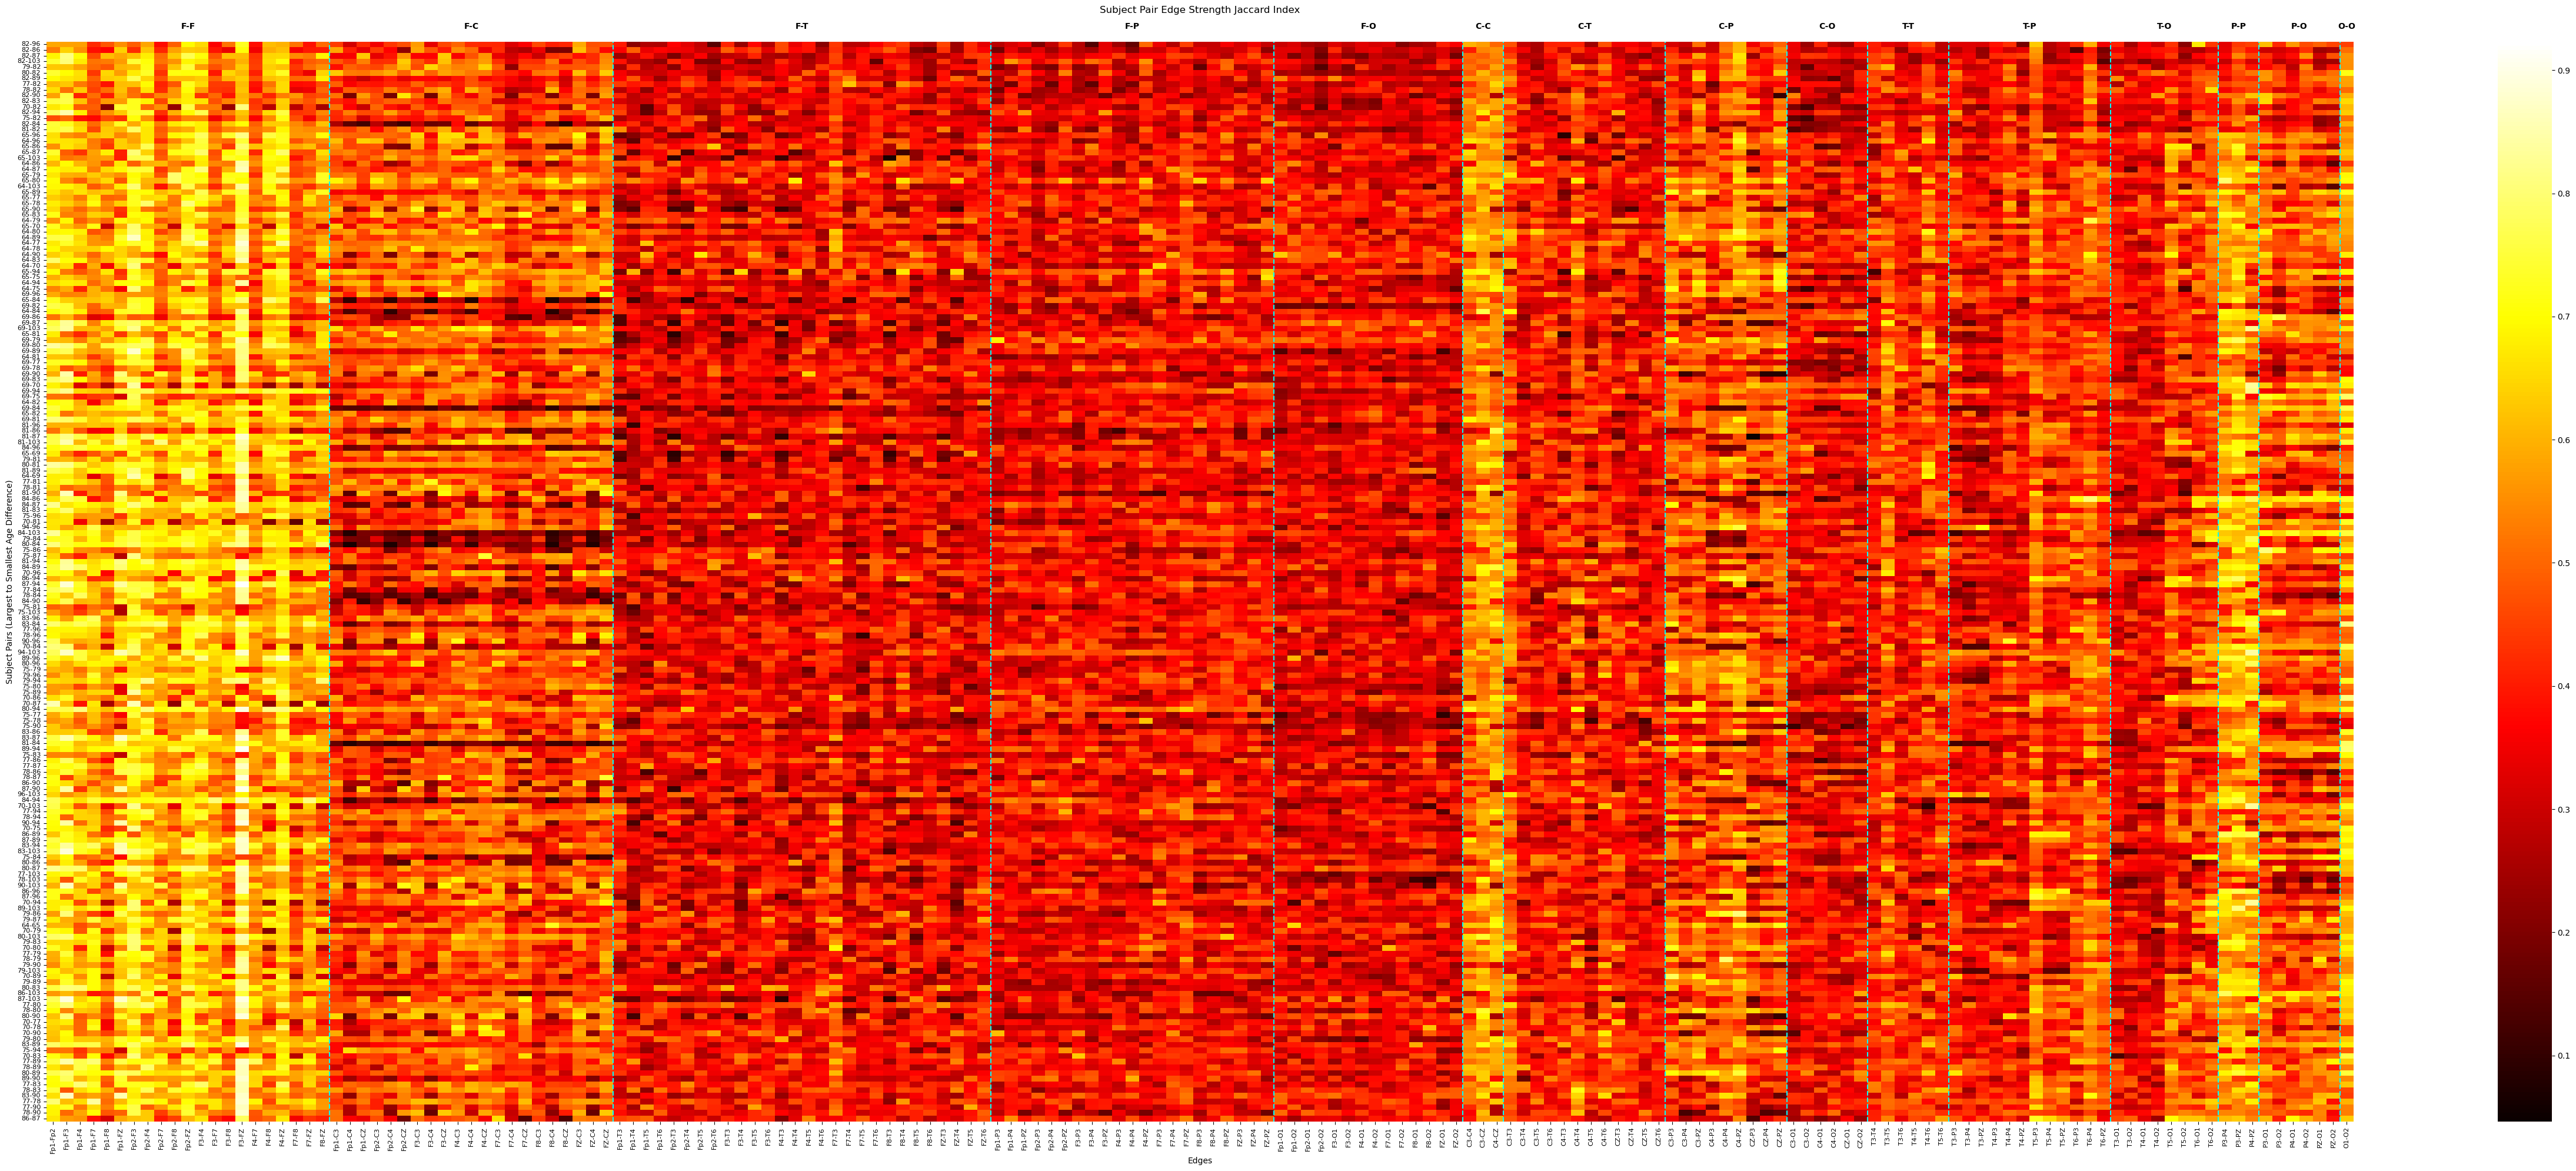

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get the age data
ages_df = pd.read_csv('../age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)]

age_dict = {}
for idx, row in ages_filtered.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

# Calculate age difference for each pair
pair_age_diff = {}
for pair in pair_jaccard_all_edges.keys():
    subj_A, subj_B = pair
    diff = abs(age_dict[subj_A] - age_dict[subj_B])
    pair_age_diff[pair] = diff

# Sort pairs by age difference descending (largest diff at top, smallest diff at bottom)
sorted_pairs = sorted(pair_age_diff.keys(), key=lambda x: pair_age_diff[x], reverse=True)

# Map original edges_list to edge_labels order
edge_to_index = {e: i for i, e in enumerate(edges_list)}

heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    p0 = str(int(pair[0].replace('sub-NORB', '')))
    p1 = str(int(pair[1].replace('sub-NORB', '')))
    yticklabels.append(f"{p0}-{p1}")
    row_data = []
    for e in edge_labels:
        u, v = e.split('-')
        edge_tuple = tuple(sorted([u, v]))
        idx = edge_to_index[edge_tuple]
        val = pair_jaccard_all_edges[pair][idx]
        row_data.append(val)
    heatmap_data.append(row_data)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 20))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=yticklabels)


# labels of the region pair at the top of the heatmap
import matplotlib.transforms as transforms

ax = plt.gca()
# Combine X in data coordinates (columns) with Y in axes coordinates (plot box height)
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)

start_idx = 0
for i in range(1, len(edge_labels) + 1):
    r_prev = f"{edge_labels[i-1].split('-')[0][0]}-{edge_labels[i-1].split('-')[1][0]}"
    r_curr = f"{edge_labels[i].split('-')[0][0]}-{edge_labels[i].split('-')[1][0]}" if i < len(edge_labels) else None
    
    if r_prev != r_curr:
        # 1. Draw vertical boundary line between region groups
        if i < len(edge_labels):
            ax.axvline(x=i, color='cyan', linestyle='--', linewidth=1.5)
            
        # 2. Calculate horizontal center of this region group
        mid_x = (start_idx + i) / 2.0
        
        # 3. Place label slightly above the top edge of the plot (y=1.01 in axes coordinates)
        ax.text(mid_x, 1.01, r_prev, transform=trans, ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        start_idx = i



plt.title('Subject Pair Edge Strength Jaccard Index', pad=35)
plt.xlabel('Edges')
plt.ylabel('Subject Pairs (Largest to Smallest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Region-wise Statistical Summary of Edge Strength Jaccard Index

This cell calculates and displays a grouped bar plot showing the percentage of Edge Strength Jaccard index values exceeding **0.75** and **0.90** for each specific brain region connection type (F-F, F-C, F-T, ..., O-O).

Connection   | Total Values   | % > 0.50   | % > 0.30  
--------------------------------------------------------
F-F          | 3,990          | 80.00      | 98.62     
F-C          | 3,990          | 35.49      | 86.59     
F-T          | 5,320          | 6.26       | 72.65     
F-P          | 3,990          | 6.34       | 77.57     
F-O          | 2,660          | 3.23       | 70.68     
C-C          | 570            | 73.86      | 97.19     
C-T          | 2,280          | 13.11      | 82.94     
C-P          | 1,710          | 41.81      | 87.49     
C-O          | 1,140          | 5.18       | 71.14     
T-T          | 1,140          | 19.30      | 90.26     
T-P          | 2,280          | 21.14      | 86.36     
T-O          | 1,520          | 17.50      | 82.04     
P-P          | 570            | 75.61      | 98.95     
P-O          | 1,140          | 35.96      | 87.46     
O-O          | 190            | 75.79      | 100.00    


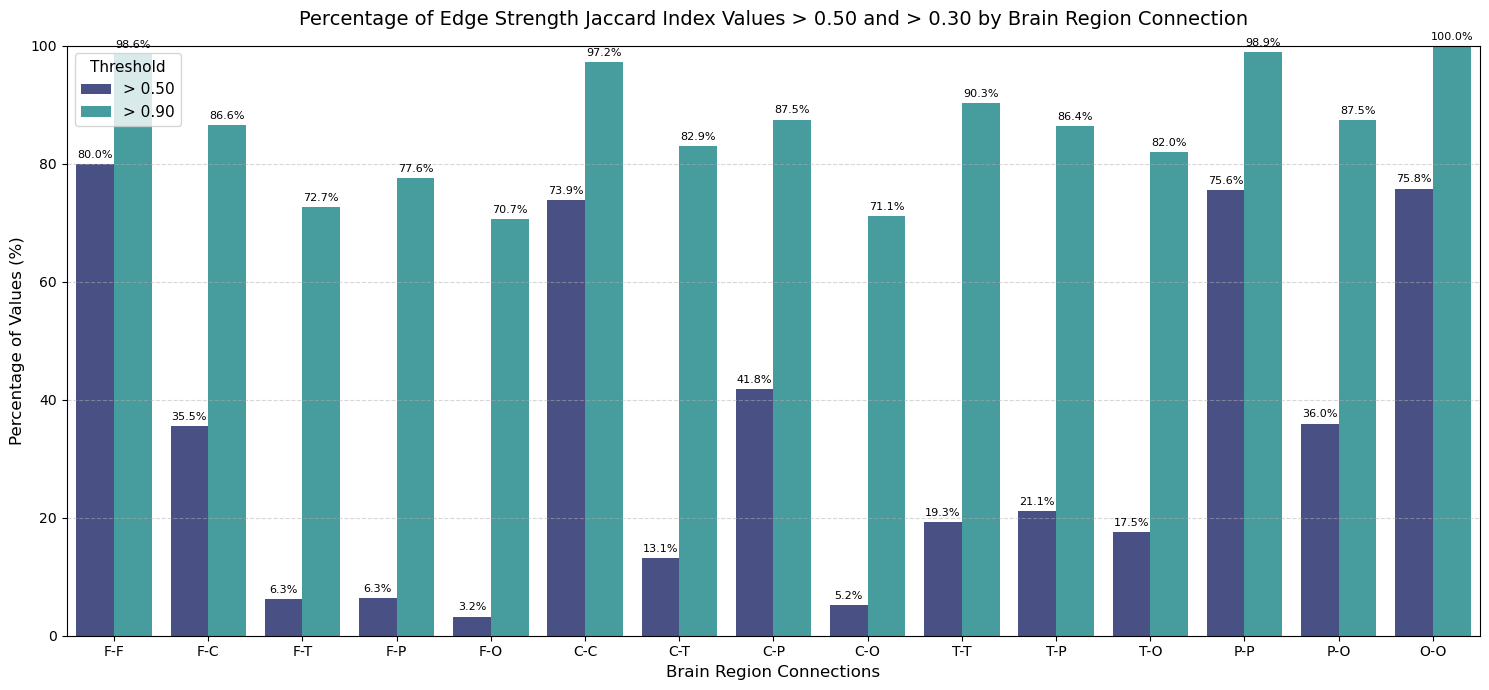

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define region order and canonical mapping
region_order = {'F': 0, 'C': 1, 'T': 2, 'P': 3, 'O': 4}

def get_region_pair(edge):
    u, v = edge.split('-')
    r1, r2 = u[0], v[0]
    if region_order.get(r1, 99) <= region_order.get(r2, 99):
        return f"{r1}-{r2}"
    else:
        return f"{r2}-{r1}"

# 2. Map every edge in edge_labels to its canonical region pair
region_groups = ['F-F', 'F-C', 'F-T', 'F-P', 'F-O', 
                 'C-C', 'C-T', 'C-P', 'C-O', 
                 'T-T', 'T-P', 'T-O', 
                 'P-P', 'P-O', 
                 'O-O']

region_values = {cat: [] for cat in region_groups}

for idx, edge in enumerate(edge_labels):
    cat = get_region_pair(edge)
    if cat in region_values:
        col_vals = heatmap_data[:, idx]
        region_values[cat].extend(col_vals)

# 3. Calculate percentages > 0.50 and > 0.30
stats_data = []

print(f"{'Connection':<12} | {'Total Values':<14} | {'% > 0.50':<10} | {'% > 0.30':<10}")
print("-" * 56)

for cat in region_groups:
    vals = np.array(region_values[cat])
    total = len(vals)
    if total > 0:
        pct_50 = (np.sum(vals > 0.50) / total) * 100.0
        pct_30 = (np.sum(vals > 0.30) / total) * 100.0
    else:
        pct_50, pct_30 = 0.0, 0.0
        
    val_str = f"{total:,}"
    print(f"{cat:<12} | {val_str:<14} | {pct_50:<10.2f} | {pct_30:<10.2f}")
    
    stats_data.append({'Region Pair': cat, 'Threshold': '> 0.50', 'Percentage': pct_50})
    stats_data.append({'Region Pair': cat, 'Threshold': '> 0.90', 'Percentage': pct_30})

df_stats = pd.DataFrame(stats_data)

# 4. Plot the grouped bar chart
plt.figure(figsize=(15, 7))
ax = sns.barplot(data=df_stats, x='Region Pair', y='Percentage', hue='Threshold', palette='mako')

plt.title('Percentage of Edge Strength Jaccard Index Values > 0.50 and > 0.30 by Brain Region Connection', fontsize=14, pad=15)
plt.xlabel('Brain Region Connections', fontsize=12)
plt.ylabel('Percentage of Values (%)', fontsize=12)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels above the bars for clear readability
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3),
                    textcoords='offset points',
                    fontsize=8, rotation=0)

plt.legend(title='Threshold', fontsize=11, title_fontsize=11)
plt.tight_layout()
plt.show()